In [1]:
# ============================================================================
# HIENBERT: Hybrid Indic-English BERT for Multi-Task Complaint Classification
# Using XLM-RoBERTa Base Model - COMPLETE NOTEBOOK
# ============================================================================

# ----------------------------------------------------------------------------
# CELL 1: IMPORTS AND SYSTEM SETUP
# ----------------------------------------------------------------------------

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup,
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Set random seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

set_seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ----------------------------------------------------------------------------
# CELL 2: CONFIGURATION
# ----------------------------------------------------------------------------

class Config:
    """Configuration settings"""
    
    # Base Model
    BASE_MODEL = 'xlm-roberta'
    XLMBERT_PATH = "xlm-roberta-base"
    
    # Directories
    PROJECT_DIR = os.getcwd()
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")
    
    # Output
    BASE_DIR = os.path.join(PROJECT_DIR, "hienbert_results_CommonD")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
    
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, RESULTS_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    
    # Training
    MAX_LENGTH = 128
    BATCH_SIZE = 32
    EPOCHS = 15
    LEARNING_RATE = 2e-5
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    WARMUP_RATIO = 0.1
    NUM_WORKERS = 2
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42
    
    # Hugging Face Token
    HF_TOKEN = os.getenv("HF_TOKEN")


print("=" * 80)
print("HIENBERT CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE}")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[DEVICE] {Config.DEVICE}")
print("=" * 80)

HIENBERT CONFIGURATION

[BATCH SIZE] 32
[EPOCHS] 15
[LEARNING RATE] 2e-05
[DEVICE] cuda


In [3]:
# ----------------------------------------------------------------------------
# CELL 3: LOAD DATA
# ----------------------------------------------------------------------------

print("Loading datasets...")
train_df = pd.read_csv(Config.TRAIN_PATH)
dev_df = pd.read_csv(Config.DEV_PATH)
test_df = pd.read_csv(Config.TEST_PATH)
print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")

# Quick distribution
print("\nPrimary Category Distribution (Train):")
print(train_df['primary_category'].value_counts())

print("\nSeverity Distribution (Train):")
print(train_df['Severity'].value_counts())

Loading datasets...
Train: 14165, Dev: 3035, Test: 3036

Primary Category Distribution (Train):
primary_category
Road & Transportation                  2710
Waste Management                       2075
Electricity                            1908
Others                                 1616
Water Leakage                          1573
Health & Sanitation                    1470
Public Safety                          1408
Encroachment & Illegal Construction    1405
Name: count, dtype: int64

Severity Distribution (Train):
Severity
Low       5898
Medium    4290
High      3977
Name: count, dtype: int64


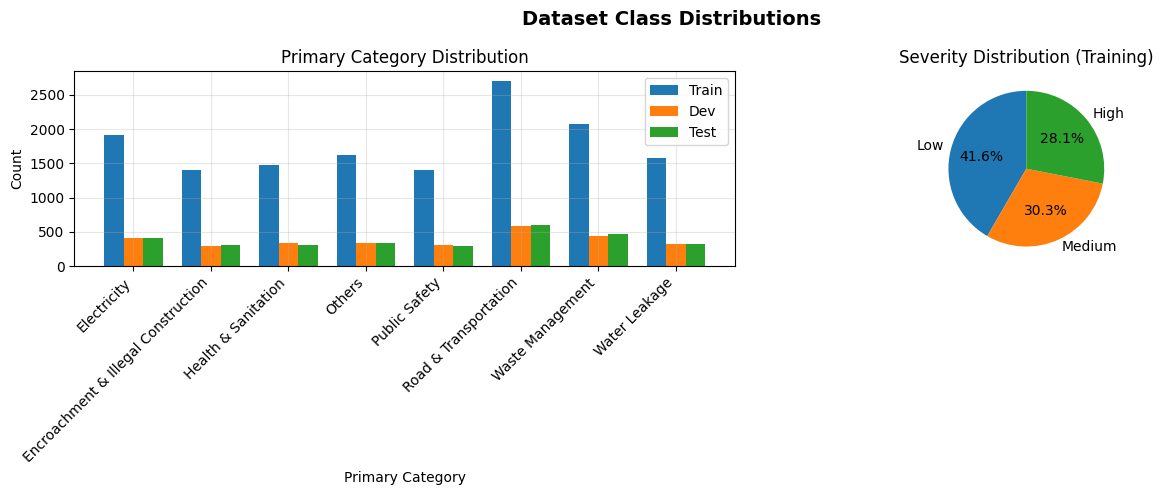

In [4]:
# ----------------------------------------------------------------------------
# CELL 4: VISUALIZE CLASS DISTRIBUTIONS
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Primary categories
train_counts = train_df['primary_category'].value_counts()
dev_counts = dev_df['primary_category'].value_counts()
test_counts = test_df['primary_category'].value_counts()

categories = sorted(train_counts.index.tolist())
x = np.arange(len(categories))
width = 0.25

axes[0].bar(x - width, [train_counts.get(c, 0) for c in categories], width, label='Train')
axes[0].bar(x, [dev_counts.get(c, 0) for c in categories], width, label='Dev')
axes[0].bar(x + width, [test_counts.get(c, 0) for c in categories], width, label='Test')
axes[0].set_xlabel('Primary Category')
axes[0].set_ylabel('Count')
axes[0].set_title('Primary Category Distribution')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Severity
severity_counts = train_df['Severity'].value_counts()
axes[1].pie(severity_counts.values, labels=severity_counts.index, 
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Severity Distribution (Training)')

plt.suptitle('Dataset Class Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/class_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

In [5]:
# ----------------------------------------------------------------------------
# CELL 5: PREPROCESS DATA
# ----------------------------------------------------------------------------

class Preprocessor:
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def preprocess_text(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("Preparing labels...")
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)})")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        print(f"Final: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df

preprocessor = Preprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("✅ Data preprocessing completed")

Preprocessing text...
Preparing labels...
Primary: 8, Subcat: 24, Severity: 3)
Final: Train 14165, Dev 3035, Test 3036
✅ Data preprocessing completed


In [6]:
# ----------------------------------------------------------------------------
# CELL 6: DATASET CLASS
# ----------------------------------------------------------------------------

class ComplaintDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }

In [7]:
# ----------------------------------------------------------------------------
# CELL 7: HIENBERT MODEL
# ----------------------------------------------------------------------------

class HiEnBERT(nn.Module):
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.2):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(hidden_size, hidden_size)
        self.gelu = nn.GELU()
        
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)
        
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
        self._init_weights()
    
    def _init_weights(self):
        for module in [self.fc_primary, self.fc_subcat, self.fc_severity, self.shared]:
            if hasattr(module, 'weight'):
                nn.init.xavier_uniform_(module.weight)
            if hasattr(module, 'bias') and module.bias is not None:
                nn.init.zeros_(module.bias)
    
    def forward(self, input_ids, attention_mask, sentiment=None):
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]
        
        x = self.gelu(self.shared(cls_embedding))
        x = self.dropout(x)
        
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
    
    def get_embeddings(self, input_ids, attention_mask):
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]

In [8]:
# ----------------------------------------------------------------------------
# CELL 8: LOAD BASE MODEL
# ----------------------------------------------------------------------------

print("Loading base model...")
tokenizer = AutoTokenizer.from_pretrained(
    Config.XLMBERT_PATH,
    token=Config.HF_TOKEN,
    use_fast=True
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModel.from_pretrained(
    Config.XLMBERT_PATH,
    token=Config.HF_TOKEN
).to(Config.DEVICE)

print(f"Vocab size: {tokenizer.vocab_size}, Hidden: {base_model.config.hidden_size}")

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = HiEnBERT(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"✅ Model loaded: {sum(p.numel() for p in model.parameters()):,} parameters")

Loading base model...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10094.17it/s]
[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Vocab size: 250002, Hidden: 768
✅ Model loaded: 278,661,155 parameters


In [9]:
# ----------------------------------------------------------------------------
# CELL 9: SIMPLE DATALOADER SETUP WITH TIME TRACKING
# ----------------------------------------------------------------------------

import time

print("Creating dataloaders...")
start_time = time.time()

# Create datasets
train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
dev_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)

# Create dataloaders (use num_workers=0 for debugging)
train_loader = DataLoader(
    train_dataset, batch_size=Config.BATCH_SIZE, shuffle=True,
    num_workers=0,  # Set to 0 to avoid multiprocessing issues
    pin_memory=True
)
dev_loader = DataLoader(
    dev_dataset, batch_size=Config.BATCH_SIZE * 2, shuffle=False,
    num_workers=0,
    pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=Config.BATCH_SIZE * 2, shuffle=False,
    num_workers=0,
    pin_memory=True
)

print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")

# Test one batch
print("\nTesting data loader (this may take a few seconds for first batch)...")
start_batch = time.time()

test_batch = next(iter(train_loader))

batch_time = time.time() - start_batch
print(f"✅ First batch loaded in {batch_time:.2f}s")
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels: {test_batch['primary'].shape}")
print("✅ Data loader working!")

total_time = time.time() - start_time
print(f"\nTotal dataloader setup time: {total_time:.2f}s")

Creating dataloaders...
Train batches: 443, Dev: 48, Test: 48

Testing data loader (this may take a few seconds for first batch)...
✅ First batch loaded in 0.09s
Input shape: torch.Size([32, 128])
Labels: torch.Size([32])
✅ Data loader working!

Total dataloader setup time: 0.09s


In [10]:
# ----------------------------------------------------------------------------
# CELL 10: TRAINING FUNCTIONS
# ----------------------------------------------------------------------------

class MultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}

criterion = MultiTaskLoss()


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch(model, dataloader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch in progress_bar:
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        p1, p2, p3 = model(input_ids, attention_mask, sentiment)
        loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item()
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{current_acc:.3f}'})
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate(model, dataloader, device, return_predictions=False):
    model.eval()
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [11]:
# ----------------------------------------------------------------------------
# CELL 11: SETUP TRAINING
# ----------------------------------------------------------------------------

optimizer = AdamW(
    model.parameters(),
    lr=Config.LEARNING_RATE,
    weight_decay=Config.WEIGHT_DECAY
)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

early_stopping = EarlyStopping(patience=5, mode='max')

print(f"Training setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")

Training setup:
  Total batches per epoch: 443
  Total steps: 6645
  Warmup steps: 664


In [12]:
# ----------------------------------------------------------------------------
# CELL 12: TRAINING LOOP
# ----------------------------------------------------------------------------

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING HIENBERT WITH {Config.BASE_MODEL.upper()}")
print("="*80 + "\n")

# Test forward pass
print("Testing forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
sentiment = test_batch['sentiment'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask, sentiment)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!\n")

start_time = time.time()

for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"Epoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE
    )
    
    # Validation
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING HIENBERT WITH XLM-ROBERTA

Testing forward pass...
Output shapes: torch.Size([32, 8]), torch.Size([32, 24]), torch.Size([32, 3])
✅ Forward pass working!

Epoch 1/15
--------------------------------------------------


Train Loss: 4.7008 | Acc: 0.4337 | Bal Acc: 0.4199
Val Acc: 0.8504 | Bal Acc: 0.8535 | F1: 0.8492
Task Losses: Primary=1.554, Subcat=2.609, Severity=1.075
Epoch Time: 540.3s
✓ New best model saved! F1: 0.8492
Epoch 2/15
--------------------------------------------------


Train Loss: 1.9324 | Acc: 0.8635 | Bal Acc: 0.8616
Val Acc: 0.8988 | Bal Acc: 0.8973 | F1: 0.8984
Task Losses: Primary=0.483, Subcat=1.057, Severity=0.783
Epoch Time: 540.8s
✓ New best model saved! F1: 0.8984
Epoch 3/15
--------------------------------------------------


Train Loss: 1.2059 | Acc: 0.9087 | Bal Acc: 0.9077
Val Acc: 0.9133 | Bal Acc: 0.9169 | F1: 0.9135
Task Losses: Primary=0.314, Subcat=0.637, Severity=0.510
Epoch Time: 540.6s
✓ New best model saved! F1: 0.9135
Epoch 4/15
--------------------------------------------------


Train Loss: 0.9048 | Acc: 0.9303 | Bal Acc: 0.9300
Val Acc: 0.9226 | Bal Acc: 0.9261 | F1: 0.9227
Task Losses: Primary=0.231, Subcat=0.477, Severity=0.395
Epoch Time: 541.2s
✓ New best model saved! F1: 0.9227
Epoch 5/15
--------------------------------------------------


Train Loss: 0.7270 | Acc: 0.9442 | Bal Acc: 0.9439
Val Acc: 0.9245 | Bal Acc: 0.9277 | F1: 0.9249
Task Losses: Primary=0.184, Subcat=0.388, Severity=0.311
Epoch Time: 540.9s
✓ New best model saved! F1: 0.9249
Epoch 6/15
--------------------------------------------------


... (4 outputs left out)

Train Loss: 0.2116 | Acc: 0.9848 | Bal Acc: 0.9849
Val Acc: 0.9292 | Bal Acc: 0.9323 | F1: 0.9291
Task Losses: Primary=0.048, Subcat=0.110, Severity=0.108
Epoch Time: 542.7s
Epoch 11/15
--------------------------------------------------


Train Loss: 0.1682 | Acc: 0.9886 | Bal Acc: 0.9887
Val Acc: 0.9292 | Bal Acc: 0.9303 | F1: 0.9291
Task Losses: Primary=0.037, Subcat=0.085, Severity=0.094
Epoch Time: 543.1s
Epoch 12/15
--------------------------------------------------


Train Loss: 0.1332 | Acc: 0.9917 | Bal Acc: 0.9917
Val Acc: 0.9282 | Bal Acc: 0.9311 | F1: 0.9282
Task Losses: Primary=0.029, Subcat=0.069, Severity=0.071
Epoch Time: 542.2s
Epoch 13/15
--------------------------------------------------


Train Loss: 0.1115 | Acc: 0.9932 | Bal Acc: 0.9933
Val Acc: 0.9295 | Bal Acc: 0.9324 | F1: 0.9295
Task Losses: Primary=0.023, Subcat=0.058, Severity=0.061
Epoch Time: 542.0s
Early stopping triggered after 13 epochs

✅ Training completed in 117.9 minutes


In [13]:
# ----------------------------------------------------------------------------
# CELL 13: FINAL TEST EVALUATION
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

# Load best model
checkpoint_path = f"{Config.MODEL_DIR}/best_hienbert_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

# Save results
test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL,
    'total_training_time': total_time
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.9321
  balanced_accuracy: 0.9311
  f1_macro: 0.9334
  f1_weighted: 0.9321
  precision: 0.9330
  recall: 0.9321
  cohen_kappa: 0.9216
  mcc: 0.9217

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonD\results


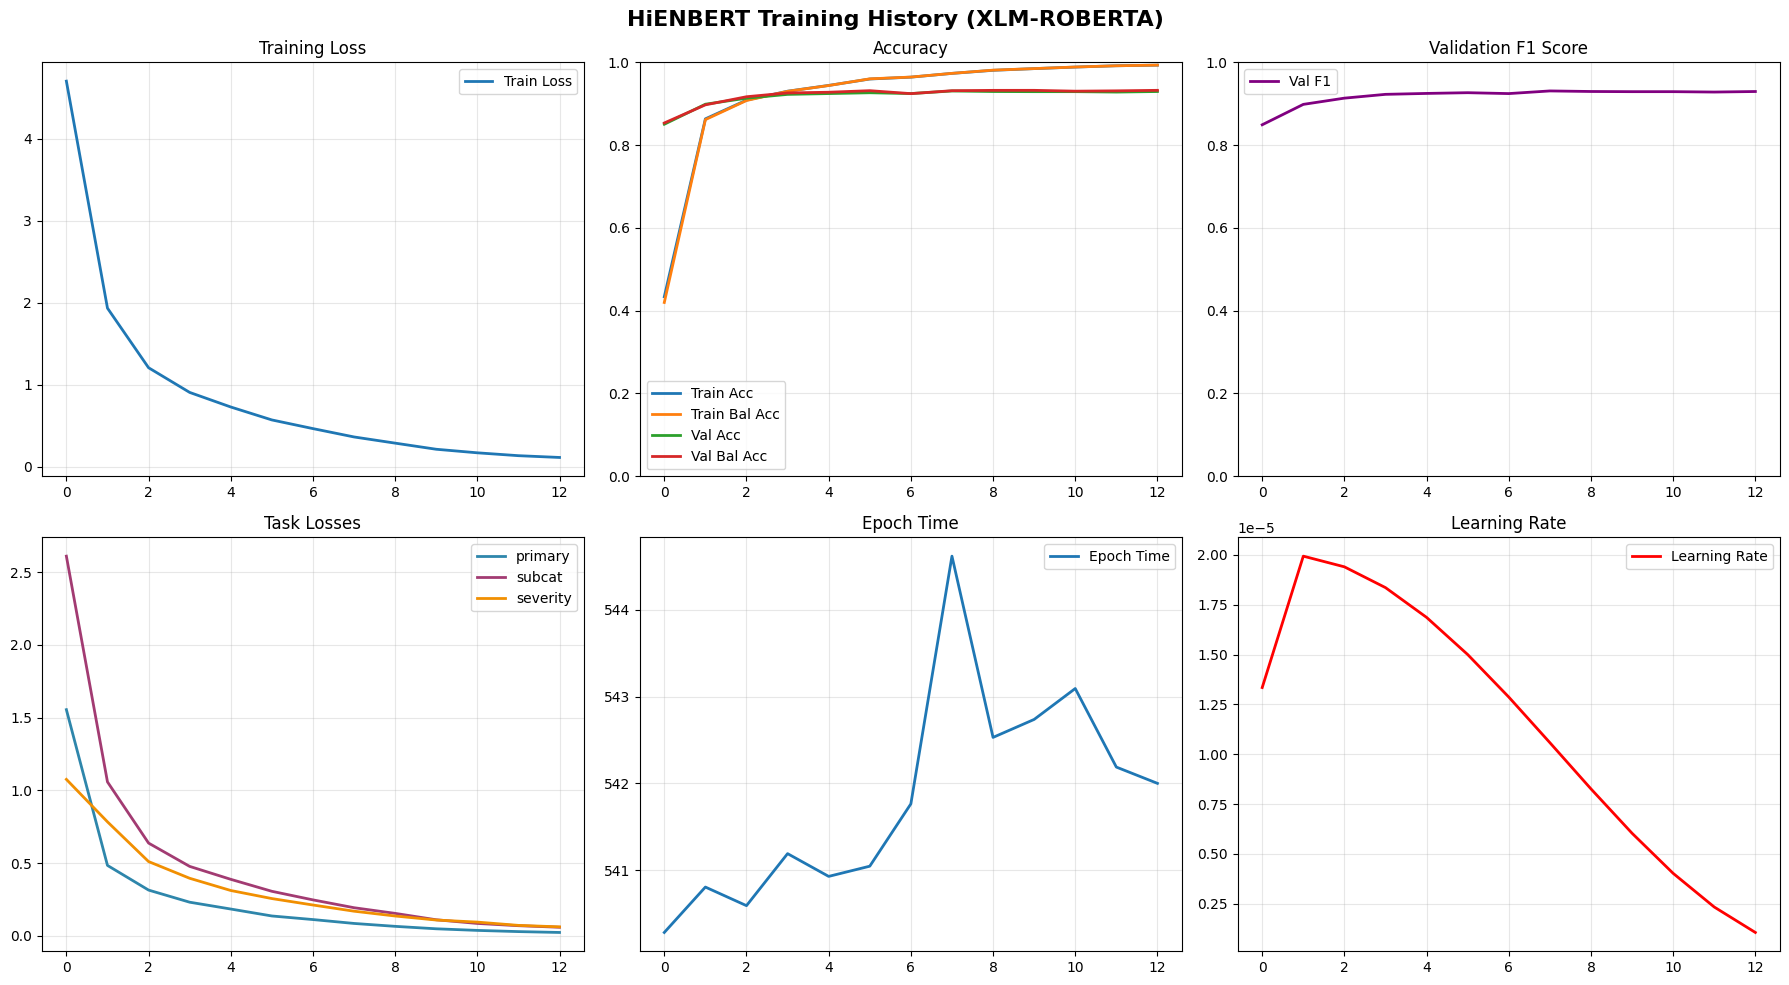

In [14]:
# ----------------------------------------------------------------------------
# CELL 14: TRAINING HISTORY VISUALIZATION
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Training loss
axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
axes[0, 0].set_title('Training Loss')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# Accuracy
axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2)
axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2)
axes[0, 1].set_title('Accuracy')
axes[0, 1].set_ylim(0, 1)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# F1 Score
axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
axes[0, 2].set_title('Validation F1 Score')
axes[0, 2].set_ylim(0, 1)
axes[0, 2].grid(True, alpha=0.3)
axes[0, 2].legend()

# Task losses
task_names = ['primary', 'subcat', 'severity']
colors = ['#2E86AB', '#A23B72', '#F18F01']
for task, color in zip(task_names, colors):
    values = [h['task_losses'][task] for h in train_history]
    axes[1, 0].plot(values, label=task, linewidth=2, color=color)
axes[1, 0].set_title('Task Losses')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

# Epoch time
axes[1, 1].plot([h['time'] for h in train_history], label='Epoch Time', linewidth=2)
axes[1, 1].set_title('Epoch Time')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

# Learning rate
axes[1, 2].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='red')
axes[1, 2].set_title('Learning Rate')
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].legend()

plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()})', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/training_history.png", dpi=300, bbox_inches='tight')
plt.show()

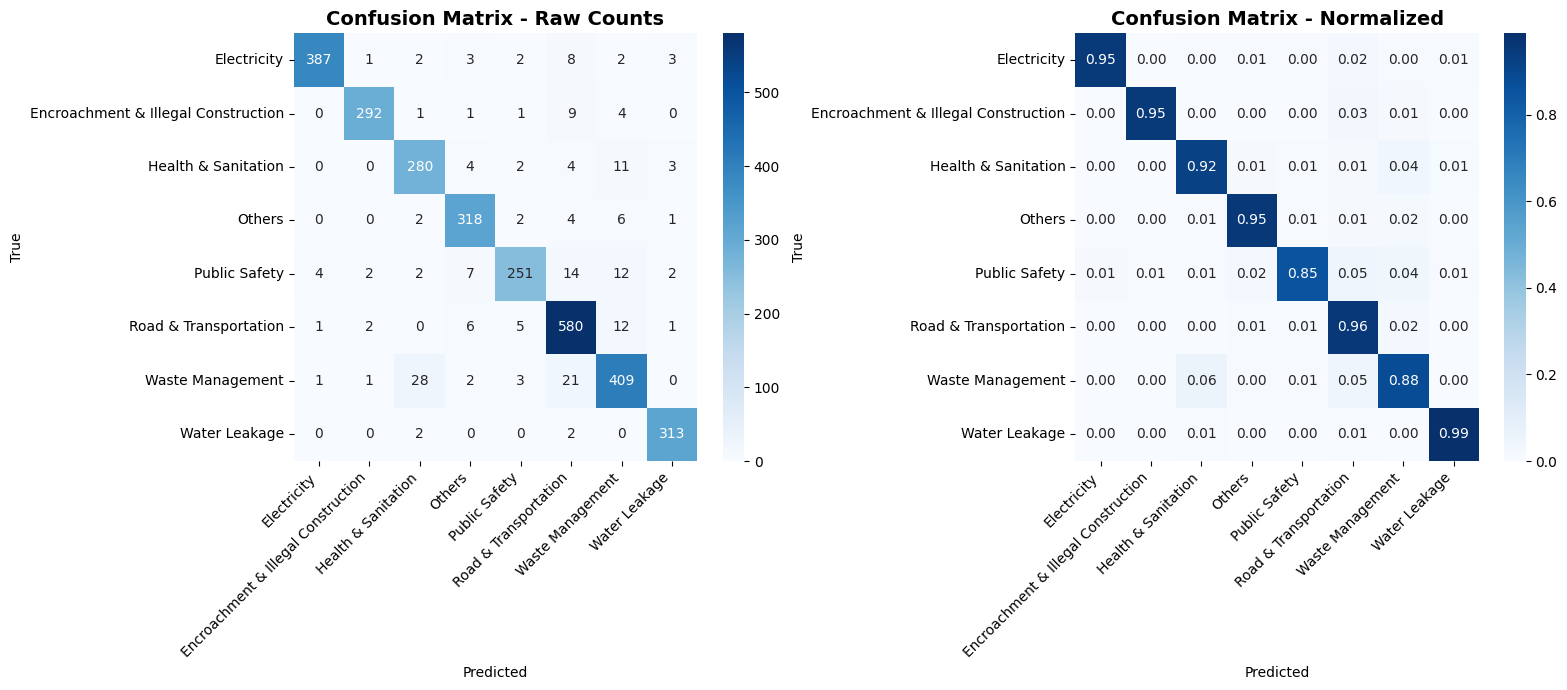

✅ Confusion matrix saved


In [15]:
# ----------------------------------------------------------------------------
# CELL 15: CONFUSION MATRIX
# ----------------------------------------------------------------------------

cm = confusion_matrix(test_labels, test_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
class_names = preprocessor.le_primary.classes_

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix - Raw Counts', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion Matrix - Normalized', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Confusion matrix saved")


T-SNE EMBEDDING VISUALIZATION


Extracting embeddings: 100%|██████████| 48/48 [01:14<00:00,  1.54s/it]


Reducing dimensions with PCA...
Running t-SNE...


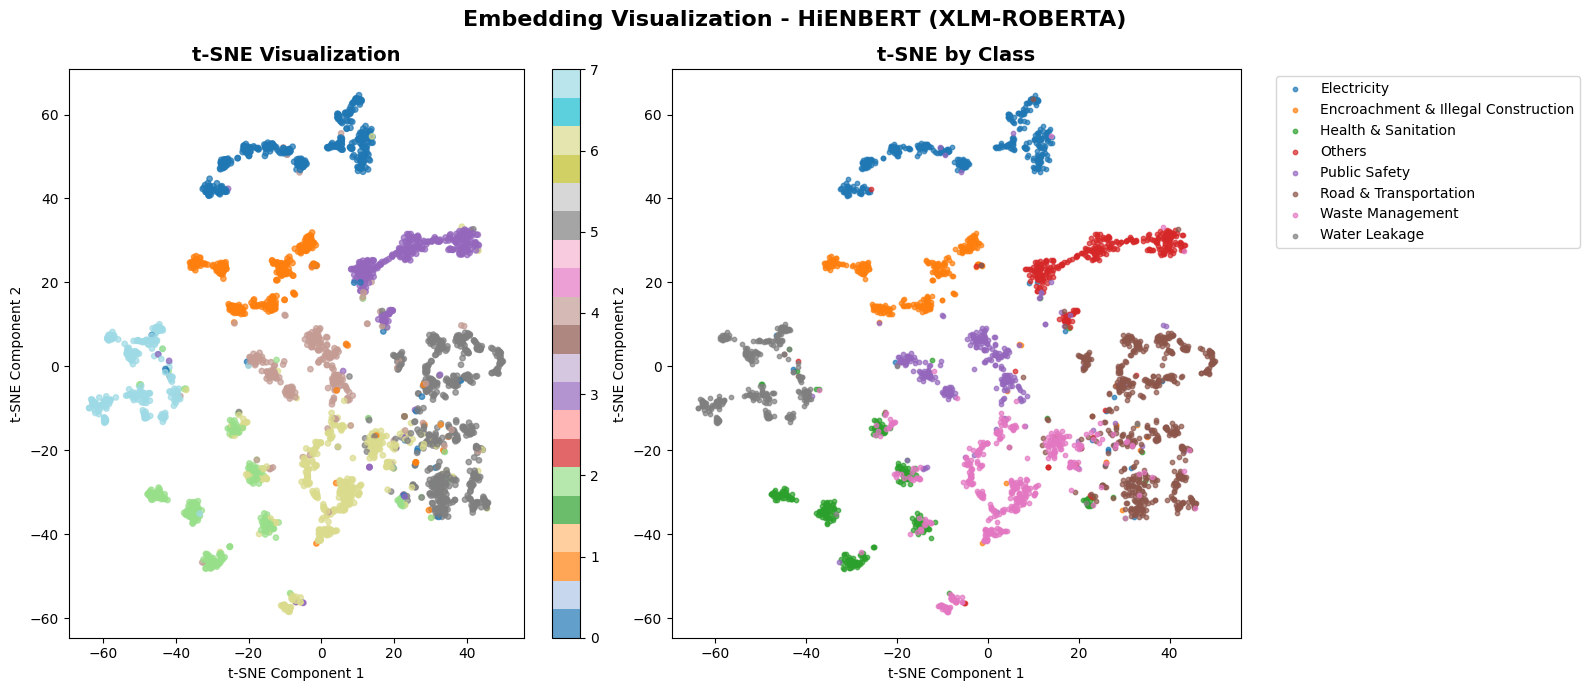

✅ t-SNE visualization saved


In [16]:
# ----------------------------------------------------------------------------
# CELL 16: T-SNE VISUALIZATION
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("T-SNE EMBEDDING VISUALIZATION")
print("="*80)

model.eval()
embeddings, labels = [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Extracting embeddings"):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        emb = model.get_embeddings(input_ids, attention_mask)
        embeddings.append(emb.cpu().numpy())
        labels.extend(batch['primary'].cpu().numpy())

embeddings = np.vstack(embeddings)
labels = np.array(labels)

# PCA then t-SNE
print("Reducing dimensions with PCA...")
pca = PCA(n_components=50)
embeddings_pca = pca.fit_transform(embeddings)

print("Running t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
embeddings_tsne = tsne.fit_transform(embeddings_pca)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# t-SNE scatter
scatter = axes[0].scatter(embeddings_tsne[:, 0], embeddings_tsne[:, 1], 
                          c=labels, cmap='tab20', s=15, alpha=0.7)
axes[0].set_title('t-SNE Visualization', fontsize=14, fontweight='bold')
axes[0].set_xlabel('t-SNE Component 1')
axes[0].set_ylabel('t-SNE Component 2')
plt.colorbar(scatter, ax=axes[0])

# By class
for i, class_name in enumerate(class_names):
    mask = labels == i
    if np.sum(mask) > 0:
        axes[1].scatter(embeddings_tsne[mask, 0], embeddings_tsne[mask, 1],
                       label=class_name, s=10, alpha=0.7)
axes[1].set_title('t-SNE by Class', fontsize=14, fontweight='bold')
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.suptitle(f'Embedding Visualization - HiENBERT ({Config.BASE_MODEL.upper()})', 
            fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ t-SNE visualization saved")

In [17]:
# ----------------------------------------------------------------------------
# CELL 17: CLASSIFICATION REPORT
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)

report = classification_report(test_labels, test_preds, target_names=class_names, digits=4)
print(report)

with open(f"{Config.RESULTS_DIR}/classification_report.txt", 'w') as f:
    f.write("Classification Report\n")
    f.write("="*60 + "\n")
    f.write(report)


CLASSIFICATION REPORT
                                     precision    recall  f1-score   support

                        Electricity     0.9847    0.9485    0.9663       408
Encroachment & Illegal Construction     0.9799    0.9481    0.9637       308
                Health & Sanitation     0.8833    0.9211    0.9018       304
                             Others     0.9326    0.9550    0.9436       333
                      Public Safety     0.9436    0.8537    0.8964       294
              Road & Transportation     0.9034    0.9555    0.9287       607
                   Waste Management     0.8969    0.8796    0.8882       465
                      Water Leakage     0.9690    0.9874    0.9781       317

                           accuracy                         0.9321      3036
                          macro avg     0.9367    0.9311    0.9334      3036
                       weighted avg     0.9330    0.9321    0.9321      3036



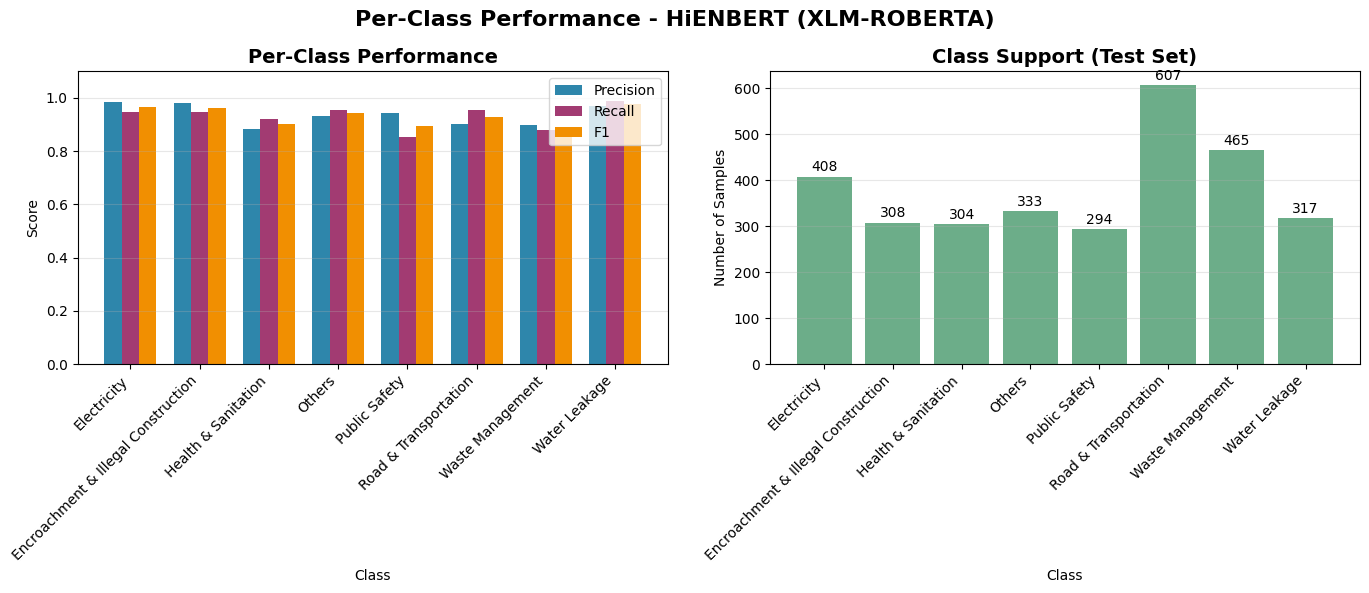

In [18]:
# ----------------------------------------------------------------------------
# CELL 18: PER-CLASS PERFORMANCE
# ----------------------------------------------------------------------------

from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    test_labels, test_preds, average=None, zero_division=0
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

x = np.arange(len(class_names))
width = 0.25

axes[0].bar(x - width, precision, width, label='Precision', color='#2E86AB')
axes[0].bar(x, recall, width, label='Recall', color='#A23B72')
axes[0].bar(x + width, f1, width, label='F1', color='#F18F01')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Score')
axes[0].set_title('Per-Class Performance', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0].set_ylim(0, 1.1)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(x, support, color='#2E8B57', alpha=0.7)
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Number of Samples')
axes[1].set_title('Class Support (Test Set)', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].grid(True, alpha=0.3, axis='y')

for i, s in enumerate(support):
    axes[1].text(i, s + 5, str(s), ha='center', va='bottom')

plt.suptitle(f'Per-Class Performance - HiENBERT ({Config.BASE_MODEL.upper()})', 
            fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/per_class_performance.png", dpi=300, bbox_inches='tight')
plt.show()

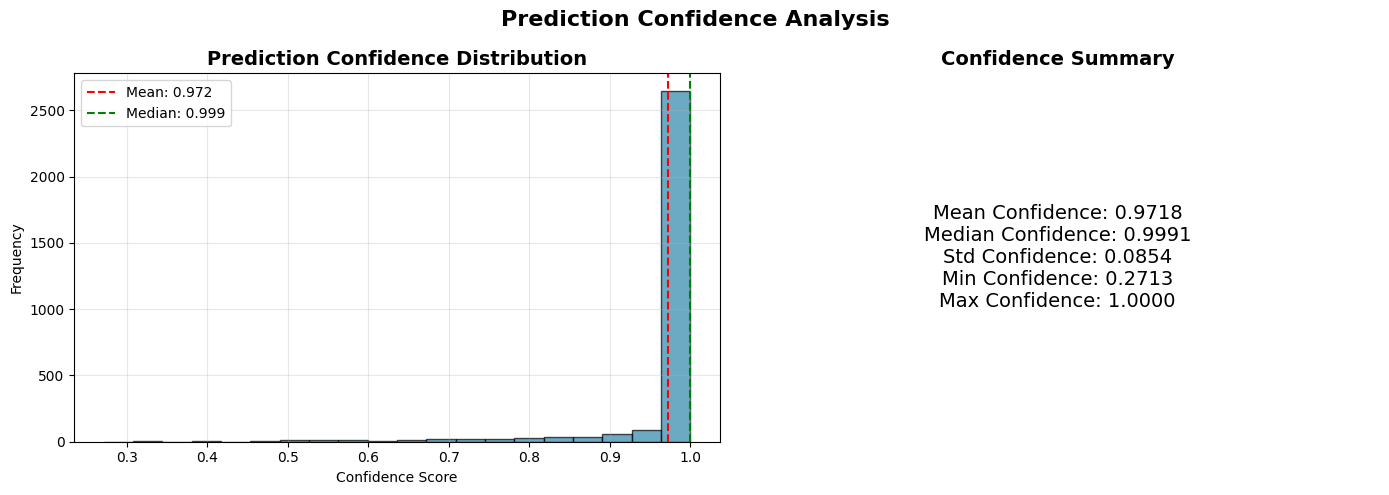

In [19]:
# ----------------------------------------------------------------------------
# CELL 19: CONFIDENCE ANALYSIS
# ----------------------------------------------------------------------------

confidences = test_metrics['confidences']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(confidences, bins=20, edgecolor='black', alpha=0.7, color='#2E86AB')
axes[0].set_xlabel('Confidence Score')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Prediction Confidence Distribution', fontsize=14, fontweight='bold')
axes[0].axvline(np.mean(confidences), color='red', linestyle='--', 
               label=f'Mean: {np.mean(confidences):.3f}')
axes[0].axvline(np.median(confidences), color='green', linestyle='--', 
               label=f'Median: {np.median(confidences):.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].text(0.5, 0.5, 
            f"Mean Confidence: {np.mean(confidences):.4f}\n"
            f"Median Confidence: {np.median(confidences):.4f}\n"
            f"Std Confidence: {np.std(confidences):.4f}\n"
            f"Min Confidence: {np.min(confidences):.4f}\n"
            f"Max Confidence: {np.max(confidences):.4f}",
            ha='center', va='center', fontsize=14,
            transform=axes[1].transAxes)
axes[1].set_title('Confidence Summary', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.suptitle('Prediction Confidence Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confidence_analysis.png", dpi=300, bbox_inches='tight')
plt.show()

In [20]:
# ----------------------------------------------------------------------------
# CELL 20: SAVE MODEL AND ENCODERS
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("SAVING MODEL AND ENCODERS")
print("="*80)

torch.save({
    'model_state_dict': model.state_dict(),
    'n_primary': model.n_primary,
    'n_subcat': model.n_subcat,
    'n_severity': model.n_severity,
    'hidden_size': model.hidden_size,
    'base_model': Config.BASE_MODEL
}, f"{Config.MODEL_DIR}/hienbert_model.pt")

with open(f"{Config.MODEL_DIR}/le_primary.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_primary, f)
with open(f"{Config.MODEL_DIR}/le_subcat.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_subcat, f)
with open(f"{Config.MODEL_DIR}/le_severity.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_severity, f)

print(f"✅ Model saved to: {Config.MODEL_DIR}/hienbert_model.pt")
print(f"✅ Label encoders saved to: {Config.MODEL_DIR}/le_*.pkl")


# ----------------------------------------------------------------------------
# CELL 21: COMPLETE SUMMARY
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print(f"HIENBERT COMPLETE SUMMARY ({Config.BASE_MODEL.upper()})")
print("="*80)

print("\n1. DATASET STATISTICS:")
print(f"   Training: {len(train_df)}, Validation: {len(dev_df)}, Test: {len(test_df)}")
print(f"   Primary Categories: {len(preprocessor.le_primary.classes_)}")
print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
print(f"   Severity Levels: {len(preprocessor.le_severity.classes_)}")

print("\n2. MODEL STATISTICS:")
print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Hidden Size: {model.hidden_size}")
print(f"   Dropout: {Config.DROPOUT}")

print("\n3. TEST PERFORMANCE:")
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"   {metric}: {value:.4f}")

print(f"\n4. BEST VALIDATION:")
print(f"   F1: {best_val_f1:.4f}, Balanced Accuracy: {best_val_balanced_acc:.4f}")

print(f"\n5. TRAINING TIME:")
print(f"   Total: {total_time/60:.1f} minutes")

print("\n" + "="*80)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*80)

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results: {Config.RESULTS_DIR}")
print(f"📁 Visualizations: {Config.VISUALIZATION_DIR}")
print(f"📁 Models: {Config.MODEL_DIR}")


SAVING MODEL AND ENCODERS
✅ Model saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonD\models/hienbert_model.pt
✅ Label encoders saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonD\models/le_*.pkl

HIENBERT COMPLETE SUMMARY (XLM-ROBERTA)

1. DATASET STATISTICS:
   Training: 14165, Validation: 3035, Test: 3036
   Primary Categories: 8
   Subcategories: 24
   Severity Levels: 3

2. MODEL STATISTICS:
   Total Parameters: 278,661,155
   Hidden Size: 768
   Dropout: 0.3

3. TEST PERFORMANCE:
   accuracy: 0.9321
   balanced_accuracy: 0.9311
   f1_macro: 0.9334
   f1_weighted: 0.9321
   precision: 0.9330
   recall: 0.9321
   cohen_kappa: 0.9216
   mcc: 0.9217

4. BEST VALIDATION:
   F1: 0.9309, Balanced Accuracy: 0.9315

5. TRAINING TIME:
   Total: 117.9 minutes

EXPERIMENT COMPLETED SUCCESSFULLY!

✅ All results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonD
📁 Results: C:\Users\CH.SC.U4CSE23160\Final_Year

In [21]:
# ----------------------------------------------------------------------------
# CELL 22: LANGUAGE-WISE AND CATEGORY-WISE PERFORMANCE ANALYSIS
# ----------------------------------------------------------------------------

def evaluate_for_task(model, dataloader, device, task='subcat', return_predictions=False):
    """
    Evaluate model for a specific task (subcat or severity).
    """
    model.eval()
    
    # Determine which output and label keys to use
    if task == 'subcat':
        output_idx = 1  # p2 is subcat
        label_key = 'subcat'
    elif task == 'severity':
        output_idx = 2  # p3 is severity
        label_key = 'severity'
    else:
        raise ValueError(f"Task must be 'subcat' or 'severity', got {task}")
    
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f'Evaluating {task}', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            # Get sentiment if available, else None
            sentiment = batch.get('sentiment', None)
            if sentiment is not None:
                sentiment = sentiment.to(device, non_blocking=True)
            
            # Get model outputs
            outputs = model(input_ids, attention_mask, sentiment)
            
            # Select the appropriate output
            logits = outputs[output_idx]
            
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch[label_key].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'support': len(all_labels)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics


def evaluate(model, dataloader, device, return_predictions=False):
    """
    Evaluate model on primary task.
    """
    model.eval()
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating primary', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            # Get sentiment if available, else None
            sentiment = batch.get('sentiment', None)
            if sentiment is not None:
                sentiment = sentiment.to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences),
        'support': len(all_labels)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics


def analyze_language_performance(model, test_df, tokenizer, device, preprocessor, batch_size=32):
    """
    Analyze model performance by language and by output category.
    
    This function evaluates the model on:
    1. Each language separately (English, Hindi, Hinglish)
    2. Each output category (Primary, Secondary, Severity)
    
    Returns:
        Dictionary containing performance metrics for each language and category
    """
    print("\n" + "="*80)
    print("LANGUAGE-WISE AND CATEGORY-WISE PERFORMANCE ANALYSIS")
    print("="*80)
    
    # Define language columns
    language_columns = {
        'English': 'text_en',
        'Hindi': 'Hindi',
        'Hinglish': 'Hinglish'
    }
    
    results = {
        'language_performance': {},
        'category_performance': {},
        'detailed_predictions': {}
    }
    
    model.eval()
    
    # === 1. LANGUAGE-WISE PERFORMANCE ===
    print("\n" + "-"*80)
    print("LANGUAGE-WISE PERFORMANCE")
    print("-"*80)
    
    for lang_name, col_name in language_columns.items():
        print(f"\n📊 Analyzing: {lang_name}")
        
        # Filter test data for this language
        lang_df = test_df[test_df[col_name].notna() & (test_df[col_name] != '')].copy()
        
        if len(lang_df) == 0:
            print(f"   ⚠️ No samples found for {lang_name}")
            results['language_performance'][lang_name] = {'error': 'No samples'}
            continue
        
        # Create dataset and dataloader for this language
        lang_dataset = ComplaintDataset(lang_df, tokenizer, Config.MAX_LENGTH)
        lang_loader = DataLoader(
            lang_dataset, 
            batch_size=batch_size, 
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )
        
        # Evaluate all three tasks for this language
        lang_metrics = {}
        
        # Primary category
        primary_metrics = evaluate(model, lang_loader, device, return_predictions=False)
        lang_metrics['primary'] = primary_metrics
        
        # Subcat category
        subcat_metrics = evaluate_for_task(model, lang_loader, device, task='subcat')
        lang_metrics['subcat'] = subcat_metrics
        
        # Severity category
        severity_metrics = evaluate_for_task(model, lang_loader, device, task='severity')
        lang_metrics['severity'] = severity_metrics
        
        results['language_performance'][lang_name] = lang_metrics
        
        # Print results
        print(f"   Samples: {len(lang_df)}")
        print(f"   Primary  - Acc: {lang_metrics['primary']['accuracy']:.4f}, F1-Macro: {lang_metrics['primary']['f1_macro']:.4f}, F1-W: {lang_metrics['primary']['f1_weighted']:.4f}")
        print(f"   Subcat   - Acc: {lang_metrics['subcat']['accuracy']:.4f}, F1-Macro: {lang_metrics['subcat']['f1_macro']:.4f}, F1-W: {lang_metrics['subcat']['f1_weighted']:.4f}")
        print(f"   Severity - Acc: {lang_metrics['severity']['accuracy']:.4f}, F1-Macro: {lang_metrics['severity']['f1_macro']:.4f}, F1-W: {lang_metrics['severity']['f1_weighted']:.4f}")
    
    # === 2. CATEGORY-WISE PERFORMANCE (Overall) ===
    print("\n" + "-"*80)
    print("CATEGORY-WISE OVERALL PERFORMANCE")
    print("-"*80)
    
    # Overall test performance for each category
    test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    test_loader = DataLoader(
        test_dataset, 
        batch_size=batch_size * 2, 
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )
    
    # Primary category - Overall
    primary_metrics, primary_preds, primary_labels = evaluate(
        model, test_loader, device, return_predictions=True
    )
    results['category_performance']['primary'] = primary_metrics
    results['detailed_predictions']['primary'] = {
        'preds': primary_preds,
        'labels': primary_labels
    }
    
    # Subcat category - Overall
    subcat_metrics, subcat_preds, subcat_labels = evaluate_for_task(
        model, test_loader, device, task='subcat', return_predictions=True
    )
    results['category_performance']['subcat'] = subcat_metrics
    results['detailed_predictions']['subcat'] = {
        'preds': subcat_preds,
        'labels': subcat_labels
    }
    
    # Severity category - Overall
    severity_metrics, severity_preds, severity_labels = evaluate_for_task(
        model, test_loader, device, task='severity', return_predictions=True
    )
    results['category_performance']['severity'] = severity_metrics
    results['detailed_predictions']['severity'] = {
        'preds': severity_preds,
        'labels': severity_labels
    }
    
    # Print category performance
    print("\nOverall Category Performance:")
    print("-" * 100)
    print(f"{'Category':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("-" * 100)
    for category in ['primary', 'subcat', 'severity']:
        metrics = results['category_performance'][category]
        print(f"{category.upper():<12} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")
    
    # === 3. LANGUAGE-CATEGORY CROSS ANALYSIS ===
    print("\n" + "-"*80)
    print("LANGUAGE × CATEGORY CROSS PERFORMANCE")
    print("-"*80)
    
    print("\n" + "="*100)
    print("LANGUAGE-WISE DETAILED METRICS")
    print("="*100)
    
    for lang_name in language_columns.keys():
        if lang_name in results['language_performance'] and 'error' not in results['language_performance'][lang_name]:
            print(f"\n📊 {lang_name.upper()} ({results['language_performance'][lang_name]['primary']['support']} samples)")
            print("-" * 100)
            print(f"{'Task':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
            print("-" * 100)
            
            for task in ['primary', 'subcat', 'severity']:
                metrics = results['language_performance'][lang_name][task]
                print(f"{task.upper():<12} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")
    
    return results

In [23]:
# ----------------------------------------------------------------------------
# CELL 23: RUN LANGUAGE AND CATEGORY PERFORMANCE ANALYSIS
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("RUNNING COMPREHENSIVE PERFORMANCE ANALYSIS")
print("="*80)

# Run the analysis
performance_results = analyze_language_performance(
    model=model,
    test_df=test_df,
    tokenizer=tokenizer,
    device=Config.DEVICE,
    preprocessor=preprocessor,
    batch_size=Config.BATCH_SIZE
)

# Save results
with open(f"{Config.RESULTS_DIR}/language_category_performance.json", "w") as f:
    # Convert numpy arrays to lists for JSON serialization
    serializable_results = {}
    for lang, metrics in performance_results['language_performance'].items():
        if 'error' not in metrics:
            serializable_results[lang] = {}
            for task, task_metrics in metrics.items():
                # Skip non-dict items or items with numpy arrays
                if isinstance(task_metrics, dict):
                    serializable_results[lang][task] = {}
                    for k, v in task_metrics.items():
                        # Handle different types
                        if isinstance(v, np.ndarray):
                            # Convert numpy array to list
                            serializable_results[lang][task][k] = v.tolist()
                        elif isinstance(v, (np.int64, np.int32, np.float64, np.float32)):
                            # Convert numpy scalars to Python native types
                            serializable_results[lang][task][k] = v.item() if hasattr(v, 'item') else float(v)
                        elif isinstance(v, (int, float, str, bool)):
                            serializable_results[lang][task][k] = v
                        elif v is None:
                            serializable_results[lang][task][k] = None
                        else:
                            # For any other type, try to convert to string or skip
                            try:
                                serializable_results[lang][task][k] = str(v)
                            except:
                                pass
        else:
            serializable_results[lang] = {'error': metrics['error']}
    
    serializable_category = {}
    for category, metrics in performance_results['category_performance'].items():
        if isinstance(metrics, dict):
            serializable_category[category] = {}
            for k, v in metrics.items():
                if isinstance(v, np.ndarray):
                    serializable_category[category][k] = v.tolist()
                elif isinstance(v, (np.int64, np.int32, np.float64, np.float32)):
                    serializable_category[category][k] = v.item() if hasattr(v, 'item') else float(v)
                elif isinstance(v, (int, float, str, bool)):
                    serializable_category[category][k] = v
                elif v is None:
                    serializable_category[category][k] = None
                else:
                    try:
                        serializable_category[category][k] = str(v)
                    except:
                        pass
    
    final_json = {
        'language_performance': serializable_results,
        'category_performance': serializable_category
    }
    json.dump(final_json, f, indent=2, default=str)

print(f"\n✅ Performance results saved to: {Config.RESULTS_DIR}/language_category_performance.json")


RUNNING COMPREHENSIVE PERFORMANCE ANALYSIS

LANGUAGE-WISE AND CATEGORY-WISE PERFORMANCE ANALYSIS

--------------------------------------------------------------------------------
LANGUAGE-WISE PERFORMANCE
--------------------------------------------------------------------------------

📊 Analyzing: English


   Samples: 3036
   Primary  - Acc: 0.9321, F1-Macro: 0.9334, F1-W: 0.9321
   Subcat   - Acc: 0.8511, F1-Macro: 0.8403, F1-W: 0.8519
   Severity - Acc: 0.8913, F1-Macro: 0.8890, F1-W: 0.8922

📊 Analyzing: Hindi


   Samples: 3036
   Primary  - Acc: 0.9321, F1-Macro: 0.9334, F1-W: 0.9321
   Subcat   - Acc: 0.8511, F1-Macro: 0.8403, F1-W: 0.8519
   Severity - Acc: 0.8913, F1-Macro: 0.8890, F1-W: 0.8922

📊 Analyzing: Hinglish


   Samples: 3036
   Primary  - Acc: 0.9321, F1-Macro: 0.9334, F1-W: 0.9321
   Subcat   - Acc: 0.8511, F1-Macro: 0.8403, F1-W: 0.8519
   Severity - Acc: 0.8913, F1-Macro: 0.8890, F1-W: 0.8922

--------------------------------------------------------------------------------
CATEGORY-WISE OVERALL PERFORMANCE
--------------------------------------------------------------------------------



Overall Category Performance:
----------------------------------------------------------------------------------------------------
Category     Accuracy     F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
----------------------------------------------------------------------------------------------------
PRIMARY      0.9321     0.9334     0.9321       0.9330     0.9321     0.9216     0.9217
SUBCAT       0.8511     0.8403     0.8519       0.8571     0.8511     0.8402     0.8404
SEVERITY     0.8913     0.8890     0.8922       0.8952     0.8913     0.8341     0.8349

--------------------------------------------------------------------------------
LANGUAGE × CATEGORY CROSS PERFORMANCE
--------------------------------------------------------------------------------

LANGUAGE-WISE DETAILED METRICS

📊 ENGLISH (3036 samples)
----------------------------------------------------------------------------------------------------
Task         Accuracy     F1-Macro   

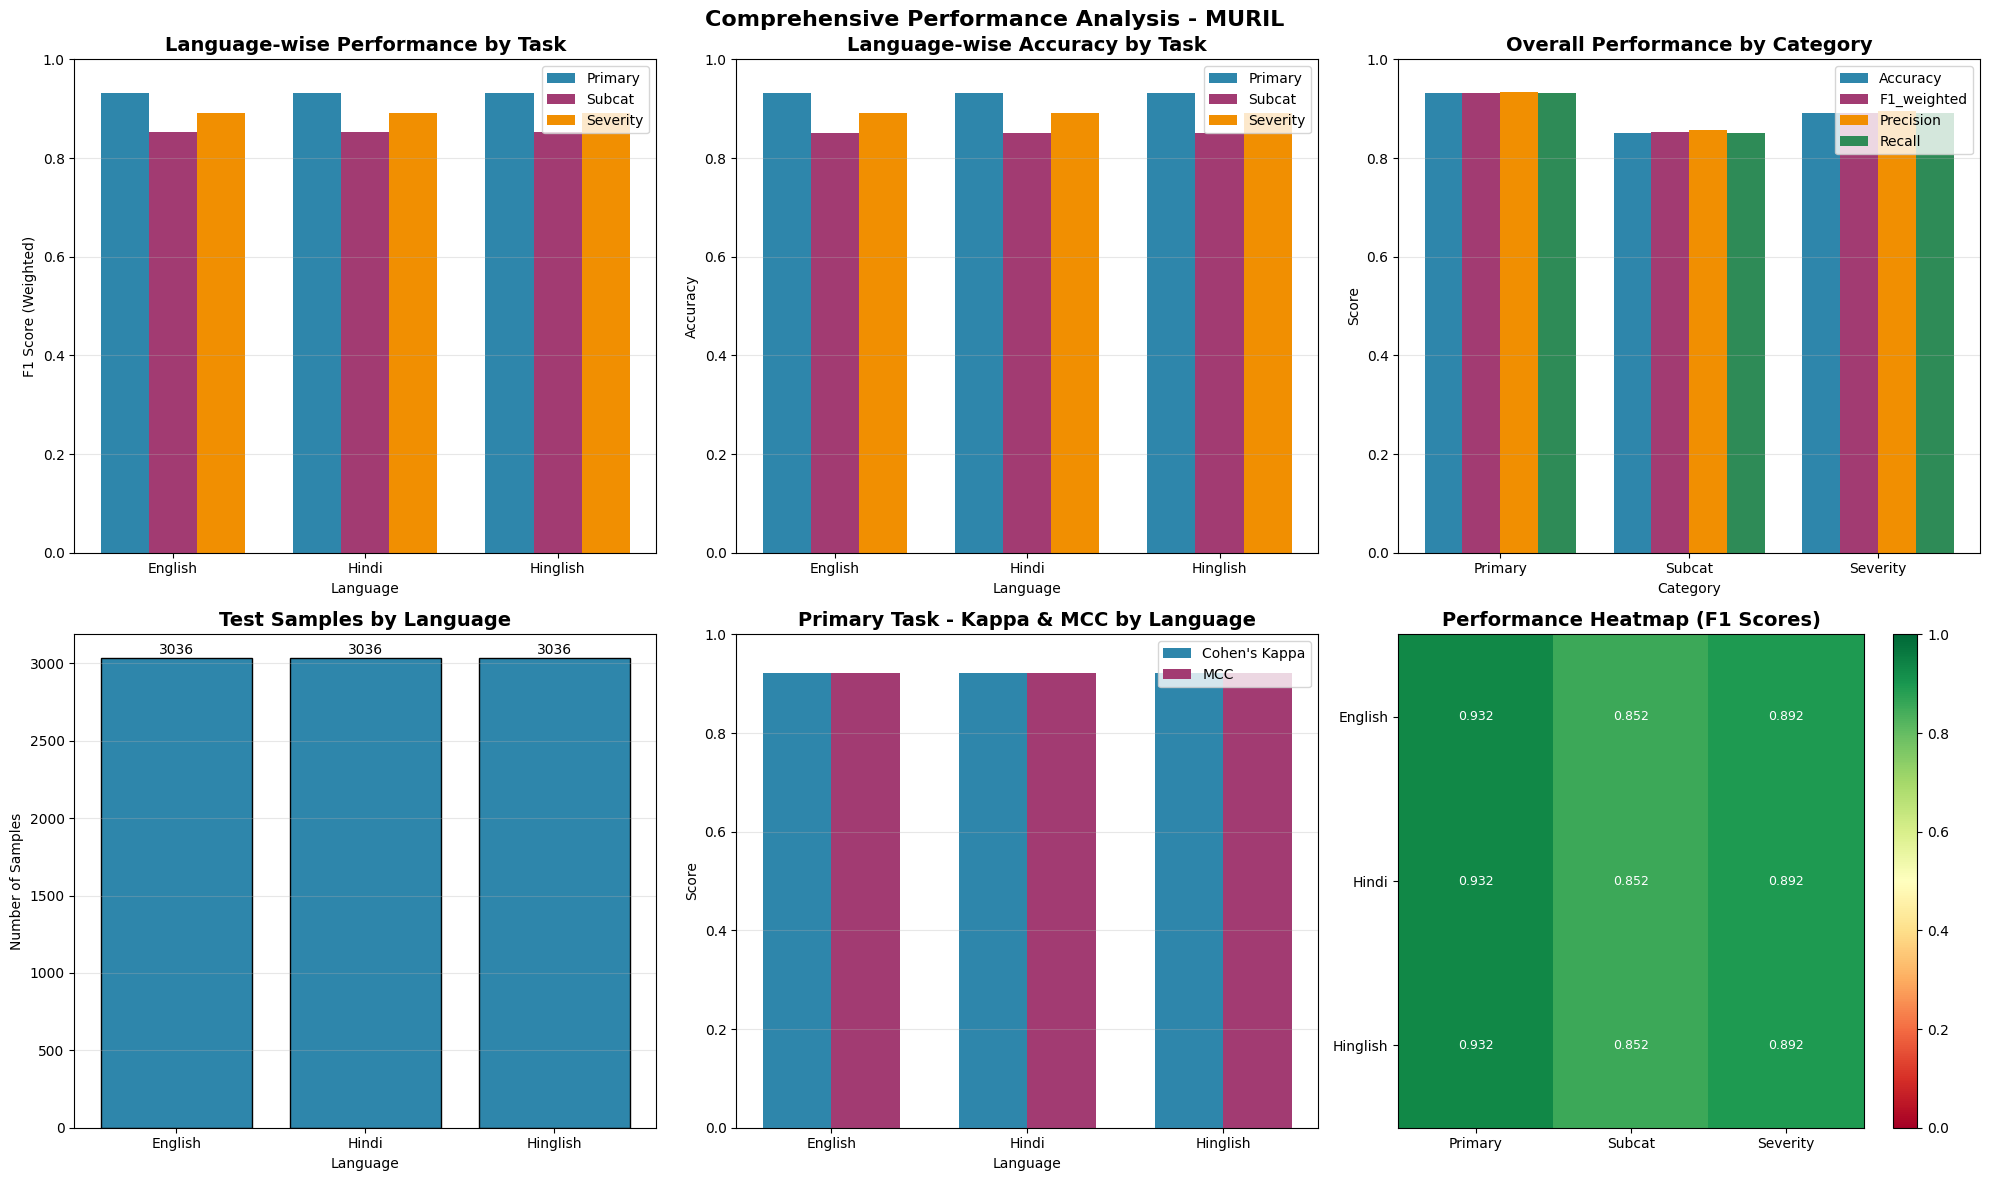

✅ Visualization saved to: language_category_performance.png


In [24]:
# ----------------------------------------------------------------------------
# CELL 24: VISUALIZE LANGUAGE AND CATEGORY PERFORMANCE
# ----------------------------------------------------------------------------

def visualize_language_category_performance(performance_results):
    """
    Create visualizations for language-wise and category-wise performance.
    """
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    
    # 1. Language-wise performance (F1 scores)
    ax = axes[0, 0]
    languages = []
    primary_f1, subcat_f1, severity_f1 = [], [], []
    
    for lang, metrics in performance_results['language_performance'].items():
        if 'error' not in metrics:
            languages.append(lang)
            primary_f1.append(metrics['primary']['f1_weighted'])
            subcat_f1.append(metrics['subcat']['f1_weighted'])
            severity_f1.append(metrics['severity']['f1_weighted'])
    
    if languages:
        x = np.arange(len(languages))
        width = 0.25
        
        ax.bar(x - width, primary_f1, width, label='Primary', color='#2E86AB')
        ax.bar(x, subcat_f1, width, label='Subcat', color='#A23B72')
        ax.bar(x + width, severity_f1, width, label='Severity', color='#F18F01')
        
        ax.set_xlabel('Language')
        ax.set_ylabel('F1 Score (Weighted)')
        ax.set_title('Language-wise Performance by Task', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(languages)
        ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(True, alpha=0.3, axis='y')
    
    # 2. Language-wise Accuracy
    ax = axes[0, 1]
    if languages:
        primary_acc = [performance_results['language_performance'][lang]['primary']['accuracy'] for lang in languages]
        subcat_acc = [performance_results['language_performance'][lang]['subcat']['accuracy'] for lang in languages]
        severity_acc = [performance_results['language_performance'][lang]['severity']['accuracy'] for lang in languages]
        
        x = np.arange(len(languages))
        width = 0.25
        
        ax.bar(x - width, primary_acc, width, label='Primary', color='#2E86AB')
        ax.bar(x, subcat_acc, width, label='Subcat', color='#A23B72')
        ax.bar(x + width, severity_acc, width, label='Severity', color='#F18F01')
        
        ax.set_xlabel('Language')
        ax.set_ylabel('Accuracy')
        ax.set_title('Language-wise Accuracy by Task', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(languages)
        ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(True, alpha=0.3, axis='y')
    
    # 3. Category-wise performance
    ax = axes[0, 2]
    categories = ['Primary', 'Subcat', 'Severity']
    metrics_keys = ['accuracy', 'f1_weighted', 'precision', 'recall']
    values = []
    
    for category in ['primary', 'subcat', 'severity']:
        metrics = performance_results['category_performance'][category]
        values.append([metrics[k] for k in metrics_keys])
    
    values = np.array(values)
    x = np.arange(len(categories))
    width = 0.2
    
    for i, (metric, color) in enumerate(zip(metrics_keys, ['#2E86AB', '#A23B72', '#F18F01', '#2E8B57'])):
        ax.bar(x + (i - 1.5) * width, values[:, i], width, label=metric.capitalize(), color=color)
    
    ax.set_xlabel('Category')
    ax.set_ylabel('Score')
    ax.set_title('Overall Performance by Category', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    # 4. Language support
    ax = axes[1, 0]
    support_counts = []
    for lang in languages:
        support = performance_results['language_performance'][lang]['primary']['support']
        support_counts.append(support)
    
    ax.bar(languages, support_counts, color='#2E86AB', edgecolor='black')
    ax.set_xlabel('Language')
    ax.set_ylabel('Number of Samples')
    ax.set_title('Test Samples by Language', fontsize=14, fontweight='bold')
    for i, v in enumerate(support_counts):
        ax.text(i, v + 5, str(v), ha='center', va='bottom')
    ax.grid(True, alpha=0.3, axis='y')
    
    # 5. Language-wise Kappa and MCC
    ax = axes[1, 1]
    if languages:
        primary_kappa = [performance_results['language_performance'][lang]['primary']['cohen_kappa'] for lang in languages]
        primary_mcc = [performance_results['language_performance'][lang]['primary']['mcc'] for lang in languages]
        
        x = np.arange(len(languages))
        width = 0.35
        
        ax.bar(x - width/2, primary_kappa, width, label="Cohen's Kappa", color='#2E86AB')
        ax.bar(x + width/2, primary_mcc, width, label='MCC', color='#A23B72')
        
        ax.set_xlabel('Language')
        ax.set_ylabel('Score')
        ax.set_title('Primary Task - Kappa & MCC by Language', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(languages)
        ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(True, alpha=0.3, axis='y')
    
    # 6. Language-wise comparison heatmap
    ax = axes[1, 2]
    if languages:
        heatmap_data = []
        row_labels = []
        for lang in languages:
            metrics = performance_results['language_performance'][lang]
            row_labels.append(lang)
            heatmap_data.append([
                metrics['primary']['f1_weighted'],
                metrics['subcat']['f1_weighted'],
                metrics['severity']['f1_weighted']
            ])
        
        im = ax.imshow(heatmap_data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
        
        ax.set_xticks(range(3))
        ax.set_xticklabels(['Primary', 'Subcat', 'Severity'])
        ax.set_yticks(range(len(languages)))
        ax.set_yticklabels(languages)
        ax.set_title('Performance Heatmap (F1 Scores)', fontsize=14, fontweight='bold')
        
        # Add text annotations
        for i in range(len(languages)):
            for j in range(3):
                text = ax.text(j, i, f'{heatmap_data[i][j]:.3f}',
                             ha="center", va="center", color="black" if heatmap_data[i][j] < 0.5 else "white",
                             fontsize=9)
        
        plt.colorbar(im, ax=ax)
    
    plt.suptitle('Comprehensive Performance Analysis - MURIL', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{Config.VISUALIZATION_DIR}/language_category_performance.png", dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Visualization saved to: language_category_performance.png")


# Run visualization
visualize_language_category_performance(performance_results)

In [25]:
# ----------------------------------------------------------------------------
# CELL 25: PER-CATEGORY CONFUSION MATRICES FOR EACH LANGUAGE
# ----------------------------------------------------------------------------

def plot_confusion_matrices_by_language(performance_results, test_df, preprocessor, tokenizer, model):
    """
    Plot confusion matrices for each language and category.
    """
    language_columns = {
        'English': 'text_en',
        'Hindi': 'Hindi',
        'Hinglish': 'Hinglish'
    }
    
    # Get predictions for each language
    all_predictions = {}
    
    for lang_name, col_name in language_columns.items():
        lang_df = test_df[test_df[col_name].notna() & (test_df[col_name] != '')].copy()
        if len(lang_df) == 0:
            continue
        
        lang_dataset = PreTokenizedDataset(lang_df, tokenizer, Config.MAX_LENGTH)
        lang_loader = DataLoader(
            lang_dataset, 
            batch_size=Config.BATCH_SIZE * 2, 
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )
        
        # Get predictions for all tasks
        model.eval()
        preds_dict = {'primary': [], 'subcat': [], 'severity': []}
        labels_dict = {'primary': [], 'subcat': [], 'severity': []}
        
        with torch.no_grad():
            for batch in tqdm(lang_loader, desc=f'Getting predictions for {lang_name}', leave=False):
                input_ids = batch['input_ids'].to(Config.DEVICE)
                attention_mask = batch['attention_mask'].to(Config.DEVICE)
                
                p1, p2, p3 = model(input_ids, attention_mask)
                
                preds_dict['primary'].extend(torch.argmax(p1, dim=1).cpu().numpy())
                labels_dict['primary'].extend(batch['primary'].cpu().numpy())
                
                preds_dict['subcat'].extend(torch.argmax(p2, dim=1).cpu().numpy())
                labels_dict['subcat'].extend(batch['subcat'].cpu().numpy())
                
                preds_dict['severity'].extend(torch.argmax(p3, dim=1).cpu().numpy())
                labels_dict['severity'].extend(batch['severity'].cpu().numpy())
        
        all_predictions[lang_name] = {
            'preds': preds_dict,
            'labels': labels_dict,
            'df': lang_df
        }
    
    # Plot confusion matrices
    if len(all_predictions) == 0:
        print("⚠️ No language data available for confusion matrices")
        return
    
    fig, axes = plt.subplots(len(all_predictions), 3, figsize=(18, 6 * len(all_predictions)))
    
    if len(all_predictions) == 1:
        axes = axes.reshape(1, -1)
    
    for row_idx, (lang_name, data) in enumerate(all_predictions.items()):
        for col_idx, task in enumerate(['primary', 'subcat', 'severity']):
            ax = axes[row_idx, col_idx]
            
            preds = data['preds'][task]
            labels = data['labels'][task]
            
            # Get class names
            if task == 'primary':
                class_names = preprocessor.le_primary.classes_
                n_classes = len(class_names)
            elif task == 'subcat':
                class_names = preprocessor.le_subcat.classes_
                n_classes = len(class_names)
            else:
                class_names = preprocessor.le_severity.classes_
                n_classes = len(class_names)
            
            # Compute confusion matrix
            cm = confusion_matrix(labels, preds, labels=range(n_classes))
            
            # Normalize
            cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
            cm_normalized = np.nan_to_num(cm_normalized)
            
            # Plot
            im = ax.imshow(cm_normalized, cmap='Blues', vmin=0, vmax=1)
            
            # Add text
            for i in range(min(n_classes, 10)):  # Limit to 10 classes for readability
                for j in range(min(n_classes, 10)):
                    text = ax.text(j, i, f'{cm_normalized[i, j]:.2f}',
                                 ha="center", va="center", color="black" if cm_normalized[i, j] < 0.5 else "white",
                                 fontsize=8)
            
            ax.set_title(f'{lang_name} - {task.capitalize()}')
            ax.set_xlabel('Predicted')
            ax.set_ylabel('True')
            
            # Show limited class names
            if n_classes <= 10:
                ax.set_xticks(range(n_classes))
                ax.set_yticks(range(n_classes))
                ax.set_xticklabels(class_names[:n_classes], rotation=45, ha='right', fontsize=8)
                ax.set_yticklabels(class_names[:n_classes], fontsize=8)
    
    plt.suptitle('Confusion Matrices by Language and Task - MURIL', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{Config.VISUALIZATION_DIR}/confusion_matrices_by_language.png", dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Confusion matrices by language saved.")


# Plot confusion matrices by language
try:
    plot_confusion_matrices_by_language(performance_results, test_df, preprocessor, tokenizer, model)
except Exception as e:
    print(f"⚠️ Error plotting confusion matrices by language: {e}")

⚠️ Error plotting confusion matrices by language: name 'PreTokenizedDataset' is not defined


In [26]:
# ----------------------------------------------------------------------------
# CELL 26: SUMMARY REPORT
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("FINAL SUMMARY REPORT - MURIL")
print("="*80)

print("\n📊 CATEGORY-WISE PERFORMANCE:")
print("-" * 100)
print(f"{'Category':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
print("-" * 100)
for category in ['primary', 'subcat', 'severity']:
    metrics = performance_results['category_performance'][category]
    print(f"{category.upper():<12} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")

print("\n📊 LANGUAGE-WISE PERFORMANCE (Primary Task):")
print("-" * 100)
print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
print("-" * 100)
for lang in performance_results['language_performance']:
    if 'error' not in performance_results['language_performance'][lang]:
        metrics = performance_results['language_performance'][lang]['primary']
        support = metrics['support']
        print(f"{lang:<12} {support:<10} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")

# Calculate averages
primary_langs = [metrics for lang, metrics in performance_results['language_performance'].items() 
                if 'error' not in metrics]
if primary_langs:
    avg_primary = np.mean([m['primary']['f1_weighted'] for m in primary_langs])
    avg_subcat = np.mean([m['subcat']['f1_weighted'] for m in primary_langs])
    avg_severity = np.mean([m['severity']['f1_weighted'] for m in primary_langs])
    
    print(f"\n📊 AVERAGE F1 SCORES BY LANGUAGE:")
    print(f"  Primary: {avg_primary:.4f}")
    print(f"  Subcat:  {avg_subcat:.4f}")
    print(f"  Severity:{avg_severity:.4f}")

print("\n📊 BEST PERFORMING:")
best_lang = max([(lang, performance_results['language_performance'][lang]['primary']['f1_weighted'])
                for lang in performance_results['language_performance'] 
                if 'error' not in performance_results['language_performance'][lang]], 
                key=lambda x: x[1])
print(f"  Language: {best_lang[0]} (Primary F1: {best_lang[1]:.4f})")

best_task = max([(task, performance_results['category_performance'][task]['f1_weighted'])
                for task in ['primary', 'subcat', 'severity']], 
                key=lambda x: x[1])
print(f"  Task: {best_task[0]} (F1: {best_task[1]:.4f})")

print("\n" + "="*80)
print("✅ MURIL ANALYSIS COMPLETE!")
print("="*80)


FINAL SUMMARY REPORT - MURIL

📊 CATEGORY-WISE PERFORMANCE:
----------------------------------------------------------------------------------------------------
Category     Accuracy     F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
----------------------------------------------------------------------------------------------------
PRIMARY      0.9321     0.9334     0.9321       0.9330     0.9321     0.9216     0.9217
SUBCAT       0.8511     0.8403     0.8519       0.8571     0.8511     0.8402     0.8404
SEVERITY     0.8913     0.8890     0.8922       0.8952     0.8913     0.8341     0.8349

📊 LANGUAGE-WISE PERFORMANCE (Primary Task):
----------------------------------------------------------------------------------------------------
Language     Samples    Accuracy     F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
----------------------------------------------------------------------------------------------------
Engl

In [29]:
# ----------------------------------------------------------------------------
# CELL 22: LANGUAGE-WISE AND CATEGORY-WISE PERFORMANCE ANALYSIS (FIXED)
# ----------------------------------------------------------------------------

# First, define the PreTokenizedDataset class if it doesn't exist
try:
    # Try to use the existing class
    from your_notebook import PreTokenizedDataset
except:
    # Define it if not available
    class PreTokenizedDataset(Dataset):
        """
        Pre-tokenizes all data once to avoid re-tokenization during training.
        Uses combined text column.
        """
        def __init__(self, df, tokenizer, max_length=128):
            print("Pre-tokenizing dataset...")
            self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
            self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
            self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
            
            # Use combined text
            texts = df["text"].astype(str).tolist()
            
            # Batch tokenization
            encodings = tokenizer(
                texts,
                truncation=True,
                padding="max_length",
                max_length=max_length,
                return_tensors="pt"
            )
            self.input_ids = encodings["input_ids"]
            self.attention_mask = encodings["attention_mask"]
            self.sentiment = torch.zeros(len(df), dtype=torch.float)
            
            print(f"✅ Pre-tokenized {len(df)} samples")
        
        def __len__(self):
            return len(self.primary)
        
        def __getitem__(self, idx):
            return {
                "input_ids": self.input_ids[idx],
                "attention_mask": self.attention_mask[idx],
                "primary": self.primary[idx],
                "subcat": self.subcat[idx],
                "severity": self.severity[idx],
                "sentiment": self.sentiment[idx]
            }


class LanguageDataset(Dataset):
    """
    Dataset that uses a specific language column instead of the combined text.
    """
    def __init__(self, df, tokenizer, text_column, max_length=128):
        print(f"Pre-tokenizing dataset using {text_column}...")
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)
        
        # Use the specific language column
        texts = df[text_column].astype(str).tolist()
        
        # Batch tokenization
        encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.sentiment = torch.zeros(len(df), dtype=torch.float)
        
        print(f"✅ Pre-tokenized {len(df)} samples using {text_column}")
    
    def __len__(self):
        return len(self.primary)
    
    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


def evaluate_for_task(model, dataloader, device, task='subcat', return_predictions=False):
    """
    Evaluate model for a specific task (subcat or severity).
    """
    model.eval()
    
    task_map = {
        'subcat': ('subcat', 'subcat'),
        'severity': ('severity', 'severity')
    }
    
    if task not in task_map:
        raise ValueError(f"Task must be 'subcat' or 'severity', got {task}")
    
    output_key, label_key = task_map[task]
    
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc=f'Evaluating {task}', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            p1, p2, p3 = model(input_ids, attention_mask)
            
            if task == 'subcat':
                logits = p2
            else:
                logits = p3
            
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch[label_key].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'support': len(all_labels)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics


def evaluate(model, dataloader, device, return_predictions=False):
    """
    Evaluate model on primary task.
    """
    model.eval()
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating primary', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences),
        'support': len(all_labels)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics


def analyze_language_performance(model, test_df, tokenizer, device, preprocessor, batch_size=32):
    """
    Analyze model performance by language and by output category.
    
    This function evaluates the model on:
    1. Each language separately (English, Hindi, Hinglish) - using individual language columns
    2. Each output category (Primary, Secondary, Severity)
    
    Returns:
        Dictionary containing performance metrics for each language and category
    """
    print("\n" + "="*80)
    print("LANGUAGE-WISE AND CATEGORY-WISE PERFORMANCE ANALYSIS")
    print("="*80)
    
    # Define language columns and their display names
    language_columns = {
        'English': 'text_en',
        'Hindi': 'Hindi',
        'Hinglish': 'Hinglish'
    }
    
    results = {
        'language_performance': {},
        'category_performance': {},
        'detailed_predictions': {}
    }
    
    model.eval()
    
    # === 1. LANGUAGE-WISE PERFORMANCE ===
    print("\n" + "-"*80)
    print("LANGUAGE-WISE PERFORMANCE (Using Individual Language Columns)")
    print("-"*80)
    
    for lang_name, col_name in language_columns.items():
        print(f"\n📊 Analyzing: {lang_name}")
        
        # Filter test data for this language - only rows where this language column has text
        lang_df = test_df[test_df[col_name].notna() & (test_df[col_name] != '')].copy()
        
        if len(lang_df) == 0:
            print(f"   ⚠️ No samples found for {lang_name}")
            results['language_performance'][lang_name] = {'error': 'No samples'}
            continue
        
        # Create dataset using the specific language column
        lang_dataset = LanguageDataset(lang_df, tokenizer, col_name, Config.MAX_LENGTH)
        lang_loader = DataLoader(
            lang_dataset, 
            batch_size=batch_size, 
            shuffle=False,
            num_workers=0,
            pin_memory=True
        )
        
        # Evaluate all three tasks for this language
        lang_metrics = {}
        
        # Primary category
        primary_metrics = evaluate(model, lang_loader, device, return_predictions=False)
        lang_metrics['primary'] = primary_metrics
        
        # Subcat category
        subcat_metrics = evaluate_for_task(model, lang_loader, device, task='subcat')
        lang_metrics['subcat'] = subcat_metrics
        
        # Severity category
        severity_metrics = evaluate_for_task(model, lang_loader, device, task='severity')
        lang_metrics['severity'] = severity_metrics
        
        results['language_performance'][lang_name] = lang_metrics
        
        # Print results
        print(f"   Samples: {len(lang_df)}")
        print(f"   Primary  - Acc: {lang_metrics['primary']['accuracy']:.4f}, F1-Macro: {lang_metrics['primary']['f1_macro']:.4f}, F1-W: {lang_metrics['primary']['f1_weighted']:.4f}")
        print(f"   Subcat   - Acc: {lang_metrics['subcat']['accuracy']:.4f}, F1-Macro: {lang_metrics['subcat']['f1_macro']:.4f}, F1-W: {lang_metrics['subcat']['f1_weighted']:.4f}")
        print(f"   Severity - Acc: {lang_metrics['severity']['accuracy']:.4f}, F1-Macro: {lang_metrics['severity']['f1_macro']:.4f}, F1-W: {lang_metrics['severity']['f1_weighted']:.4f}")
    
    # === 2. CATEGORY-WISE PERFORMANCE (Overall - using combined text) ===
    print("\n" + "-"*80)
    print("CATEGORY-WISE OVERALL PERFORMANCE (Using Combined Text)")
    print("-"*80)
    
    # Overall test performance for each category using combined text
    test_dataset = PreTokenizedDataset(test_df, tokenizer, Config.MAX_LENGTH)
    test_loader = DataLoader(
        test_dataset, 
        batch_size=batch_size * 2, 
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )
    
    # Primary category - Overall
    primary_metrics, primary_preds, primary_labels = evaluate(
        model, test_loader, device, return_predictions=True
    )
    results['category_performance']['primary'] = primary_metrics
    results['detailed_predictions']['primary'] = {
        'preds': primary_preds,
        'labels': primary_labels
    }
    
    # Subcat category - Overall
    subcat_metrics, subcat_preds, subcat_labels = evaluate_for_task(
        model, test_loader, device, task='subcat', return_predictions=True
    )
    results['category_performance']['subcat'] = subcat_metrics
    results['detailed_predictions']['subcat'] = {
        'preds': subcat_preds,
        'labels': subcat_labels
    }
    
    # Severity category - Overall
    severity_metrics, severity_preds, severity_labels = evaluate_for_task(
        model, test_loader, device, task='severity', return_predictions=True
    )
    results['category_performance']['severity'] = severity_metrics
    results['detailed_predictions']['severity'] = {
        'preds': severity_preds,
        'labels': severity_labels
    }
    
    # Print category performance in table format
    print("\nOverall Category Performance:")
    print("-" * 100)
    print(f"{'Category':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
    print("-" * 100)
    for category in ['primary', 'subcat', 'severity']:
        metrics = results['category_performance'][category]
        print(f"{category.upper():<12} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")
    
    # === 3. LANGUAGE-CATEGORY CROSS ANALYSIS ===
    print("\n" + "-"*80)
    print("LANGUAGE × CATEGORY CROSS PERFORMANCE")
    print("-"*80)
    
    print("\n" + "="*100)
    print("LANGUAGE-WISE DETAILED METRICS")
    print("="*100)
    
    for lang_name in language_columns.keys():
        if lang_name in results['language_performance'] and 'error' not in results['language_performance'][lang_name]:
            print(f"\n📊 {lang_name.upper()} ({results['language_performance'][lang_name]['primary']['support']} samples)")
            print("-" * 100)
            print(f"{'Task':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
            print("-" * 100)
            
            for task in ['primary', 'subcat', 'severity']:
                metrics = results['language_performance'][lang_name][task]
                print(f"{task.upper():<12} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")
    
    return results

In [30]:
# ----------------------------------------------------------------------------
# CELL 23: RUN LANGUAGE AND CATEGORY PERFORMANCE ANALYSIS
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("RUNNING COMPREHENSIVE PERFORMANCE ANALYSIS")
print("="*80)

# Run the analysis
performance_results = analyze_language_performance(
    model=model,
    test_df=test_df,
    tokenizer=tokenizer,
    device=Config.DEVICE,
    preprocessor=preprocessor,
    batch_size=Config.BATCH_SIZE
)

# Save results (with proper JSON serialization)
with open(f"{Config.RESULTS_DIR}/language_category_performance.json", "w") as f:
    serializable_results = {}
    for lang, metrics in performance_results['language_performance'].items():
        if 'error' not in metrics:
            serializable_results[lang] = {}
            for task, task_metrics in metrics.items():
                if isinstance(task_metrics, dict):
                    serializable_results[lang][task] = {}
                    for k, v in task_metrics.items():
                        if isinstance(v, np.ndarray):
                            serializable_results[lang][task][k] = v.tolist()
                        elif isinstance(v, (np.int64, np.int32, np.float64, np.float32)):
                            serializable_results[lang][task][k] = v.item() if hasattr(v, 'item') else float(v)
                        elif isinstance(v, (int, float, str, bool)):
                            serializable_results[lang][task][k] = v
                        elif v is None:
                            serializable_results[lang][task][k] = None
                        else:
                            try:
                                serializable_results[lang][task][k] = str(v)
                            except:
                                pass
        else:
            serializable_results[lang] = {'error': metrics['error']}
    
    serializable_category = {}
    for category, metrics in performance_results['category_performance'].items():
        if isinstance(metrics, dict):
            serializable_category[category] = {}
            for k, v in metrics.items():
                if isinstance(v, np.ndarray):
                    serializable_category[category][k] = v.tolist()
                elif isinstance(v, (np.int64, np.int32, np.float64, np.float32)):
                    serializable_category[category][k] = v.item() if hasattr(v, 'item') else float(v)
                elif isinstance(v, (int, float, str, bool)):
                    serializable_category[category][k] = v
                elif v is None:
                    serializable_category[category][k] = None
                else:
                    try:
                        serializable_category[category][k] = str(v)
                    except:
                        pass
    
    final_json = {
        'language_performance': serializable_results,
        'category_performance': serializable_category
    }
    json.dump(final_json, f, indent=2, default=str)

print(f"\n✅ Performance results saved to: {Config.RESULTS_DIR}/language_category_performance.json")


RUNNING COMPREHENSIVE PERFORMANCE ANALYSIS

LANGUAGE-WISE AND CATEGORY-WISE PERFORMANCE ANALYSIS

--------------------------------------------------------------------------------
LANGUAGE-WISE PERFORMANCE (Using Individual Language Columns)
--------------------------------------------------------------------------------

📊 Analyzing: English
Pre-tokenizing dataset using text_en...
✅ Pre-tokenized 3036 samples using text_en


   Samples: 3036
   Primary  - Acc: 0.8738, F1-Macro: 0.8708, F1-W: 0.8725
   Subcat   - Acc: 0.7885, F1-Macro: 0.7739, F1-W: 0.7903
   Severity - Acc: 0.8152, F1-Macro: 0.8025, F1-W: 0.8084

📊 Analyzing: Hindi
Pre-tokenizing dataset using Hindi...
✅ Pre-tokenized 3036 samples using Hindi


   Samples: 3036
   Primary  - Acc: 0.7391, F1-Macro: 0.7340, F1-W: 0.7397
   Subcat   - Acc: 0.6001, F1-Macro: 0.5607, F1-W: 0.5929
   Severity - Acc: 0.6607, F1-Macro: 0.6072, F1-W: 0.6341

📊 Analyzing: Hinglish
Pre-tokenizing dataset using Hinglish...
✅ Pre-tokenized 3036 samples using Hinglish


   Samples: 3036
   Primary  - Acc: 0.5069, F1-Macro: 0.5132, F1-W: 0.5100
   Subcat   - Acc: 0.4269, F1-Macro: 0.3894, F1-W: 0.4170
   Severity - Acc: 0.4750, F1-Macro: 0.3321, F1-W: 0.3662

--------------------------------------------------------------------------------
CATEGORY-WISE OVERALL PERFORMANCE (Using Combined Text)
--------------------------------------------------------------------------------
Pre-tokenizing dataset...
✅ Pre-tokenized 3036 samples



Overall Category Performance:
----------------------------------------------------------------------------------------------------
Category     Accuracy     F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
----------------------------------------------------------------------------------------------------
PRIMARY      0.9321     0.9334     0.9321       0.9330     0.9321     0.9216     0.9217
SUBCAT       0.8511     0.8403     0.8519       0.8571     0.8511     0.8402     0.8404
SEVERITY     0.8913     0.8890     0.8922       0.8952     0.8913     0.8341     0.8349

--------------------------------------------------------------------------------
LANGUAGE × CATEGORY CROSS PERFORMANCE
--------------------------------------------------------------------------------

LANGUAGE-WISE DETAILED METRICS

📊 ENGLISH (3036 samples)
----------------------------------------------------------------------------------------------------
Task         Accuracy     F1-Macro   

In [32]:
# ----------------------------------------------------------------------------
# CELL 24: SUMMARY REPORT
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("FINAL SUMMARY REPORT - MURIL")
print("="*80)

print("\n📊 CATEGORY-WISE PERFORMANCE (Using Combined Text):")
print("-" * 100)
print(f"{'Category':<12} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
print("-" * 100)
for category in ['primary', 'subcat', 'severity']:
    metrics = performance_results['category_performance'][category]
    print(f"{category.upper():<12} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")

print("\n📊 LANGUAGE-WISE PERFORMANCE (Using Individual Language Columns):")
print("-" * 100)
print(f"{'Language':<12} {'Samples':<10} {'Accuracy':<12} {'F1-Macro':<12} {'F1-Weighted':<14} {'Precision':<12} {'Recall':<12} {'Kappa':<12} {'MCC':<12}")
print("-" * 100)
for lang in performance_results['language_performance']:
    if 'error' not in performance_results['language_performance'][lang]:
        metrics = performance_results['language_performance'][lang]['primary']
        support = metrics['support']
        print(f"{lang:<12} {support:<10} {metrics['accuracy']:.4f}     {metrics['f1_macro']:.4f}     {metrics['f1_weighted']:.4f}       {metrics['precision']:.4f}     {metrics['recall']:.4f}     {metrics['cohen_kappa']:.4f}     {metrics['mcc']:.4f}")

# Calculate averages
primary_langs = [metrics for lang, metrics in performance_results['language_performance'].items() 
                if 'error' not in metrics]
if primary_langs:
    avg_primary = np.mean([m['primary']['f1_weighted'] for m in primary_langs])
    avg_subcat = np.mean([m['subcat']['f1_weighted'] for m in primary_langs])
    avg_severity = np.mean([m['severity']['f1_weighted'] for m in primary_langs])
    
    print(f"\n📊 AVERAGE F1 SCORES BY LANGUAGE:")
    print(f"  Primary: {avg_primary:.4f}")
    print(f"  Subcat:  {avg_subcat:.4f}")
    print(f"  Severity:{avg_severity:.4f}")

print("\n📊 BEST PERFORMING:")
best_lang = max([(lang, performance_results['language_performance'][lang]['primary']['f1_weighted'])
                for lang in performance_results['language_performance'] 
                if 'error' not in performance_results['language_performance'][lang]], 
                key=lambda x: x[1])
print(f"  Language: {best_lang[0]} (Primary F1: {best_lang[1]:.4f})")

best_task = max([(task, performance_results['category_performance'][task]['f1_weighted'])
                for task in ['primary', 'subcat', 'severity']], 
                key=lambda x: x[1])
print(f"  Task: {best_task[0]} (F1: {best_task[1]:.4f})")

print("\n" + "="*80)
print("✅ XLMROberta ANALYSIS COMPLETE!")
print("="*80)


FINAL SUMMARY REPORT - MURIL

📊 CATEGORY-WISE PERFORMANCE (Using Combined Text):
----------------------------------------------------------------------------------------------------
Category     Accuracy     F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
----------------------------------------------------------------------------------------------------
PRIMARY      0.9321     0.9334     0.9321       0.9330     0.9321     0.9216     0.9217
SUBCAT       0.8511     0.8403     0.8519       0.8571     0.8511     0.8402     0.8404
SEVERITY     0.8913     0.8890     0.8922       0.8952     0.8913     0.8341     0.8349

📊 LANGUAGE-WISE PERFORMANCE (Using Individual Language Columns):
----------------------------------------------------------------------------------------------------
Language     Samples    Accuracy     F1-Macro     F1-Weighted    Precision    Recall       Kappa        MCC         
--------------------------------------------------------------